# Mô hình nhận giọng Bắc, Trung, Nam thế nào khi có tiếng ồn?

Notebook đọc các kết quả đã lưu. Chọn **Run All** để xem bảng và biểu đồ; không cần chạy lại mô hình.

### Những từ cần biết
- **Bản gốc:** đoạn nói trước khi chương trình thêm tiếng ồn; bản thân đoạn này vẫn có thể có tiếng nền.
- **Tập kiểm tra trong lúc phát triển (validation):** dữ liệu giúp phân tích và chọn cách cải thiện. Đây chưa phải tập test dùng để đánh giá cuối cùng.
- **Độ chính xác (Accuracy):** trong tất cả đoạn nói, mô hình đoán đúng bao nhiêu phần trăm.
- **Điểm F1 trung bình ba miền (Macro-F1):** tính điểm F1 riêng cho Bắc, Trung, Nam rồi lấy trung bình, mỗi miền có vai trò như nhau. F1 xét cả việc nhận đúng một miền và việc gán nhầm các miền khác thành miền đó. Điểm cao hơn tốt hơn; đây không phải tỷ lệ đoán đúng toàn bộ dữ liệu.
- **Mức tiếng ồn (SNR):** 20 dB ít nhiễu hơn 10 dB; 0 dB có nhiễu mạnh hơn. Cùng SNR, hai tệp nhiễu vẫn có thể ảnh hưởng khác nhau.
- **Điểm phần trăm:** từ 90% xuống 70% là giảm 20 điểm phần trăm.
- **Lần chọn đoạn nhiễu (repeat):** thử lại bằng đoạn cắt khác của cùng tệp nhiễu, không phải huấn luyện lại mô hình.

Mỗi đường trên biểu đồ là một tệp nhiễu cụ thể. Nhiều phiên bản của một đoạn nói vẫn thuộc cùng một bản ghi, không được coi là nhiều người nói mới.

In [20]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import confusion_matrix
from IPython.display import display, Markdown

# Chọn cố định lần chạy cần phân tích, tránh vô tình đọc một lần chạy khác.
RUN_NAME = '20261018_221428_db87c290'
SAVE_FIGURES = False  # Đổi True nếu muốn xuất thêm ảnh PNG khi chạy notebook.

possible_project_folders = [Path.cwd(), Path.cwd() / 'Code' / 'ViSpeech']
project_folder = next((folder for folder in possible_project_folders
                       if (folder / 'logs' / 'noise_robustness' / RUN_NAME).is_dir()), None)
if project_folder is None:
    raise FileNotFoundError('Mở notebook tại Code/ViSpeech hoặc thư mục gốc LuanVan01.')
results_folder = project_folder / 'logs' / 'noise_robustness' / RUN_NAME
summary = pd.read_csv(results_folder / 'summary.csv')
predictions = pd.read_csv(results_folder / 'predictions.csv')
noise_files = pd.read_csv(results_folder / 'noise_metadata.csv')
with (results_folder / 'run_info.json').open(encoding='utf-8') as file:
    run_information = json.load(file)
if run_information.get('status') != 'completed':
    raise ValueError('Lần chạy chưa hoàn tất; không phân tích kết quả dở dang.')

# Dùng nguyên tên tệp cho chú thích; không tự đoán loại nhiễu.
noise_names = {row.noise_id: Path(row.path.replace('\\', '/')).stem
               for row in noise_files.itertuples()}
noise_ids = noise_files['noise_id'].tolist()
snr_levels = sorted(summary.loc[summary.condition.eq('noisy'), 'snr_db'].unique(), reverse=True)
dialect_names = ['Bắc', 'Trung', 'Nam']
original_predictions = predictions[predictions.condition.eq('original')].copy()
noisy_predictions = predictions[predictions.condition.eq('noisy')].copy()
original_summary = summary[summary.condition.eq('original')]
if len(original_summary) != 1 or original_predictions.audio_id.duplicated().any():
    raise ValueError('Mỗi mã đoạn nói phải có đúng một dự đoán bản gốc.')
if noisy_predictions.duplicated(['audio_id', 'noise_id', 'snr_db', 'repeat_id']).any():
    raise ValueError('Cùng đoạn nói, tệp nhiễu, mức SNR và lần thử bị ghi kết quả nhiều hơn một lần.')
for key, group in noisy_predictions.groupby(['noise_id', 'snr_db', 'repeat_id']):
    if set(group.audio_id) != set(original_predictions.audio_id):
        raise ValueError(f'Điều kiện {key} không đủ cùng các mẫu bản gốc.')

baseline_f1 = float(original_summary.iloc[0].macro_f1)
noisy_summary = summary[summary.condition.eq('noisy')].copy()
noisy_summary['f1_drop_points'] = (baseline_f1 - noisy_summary.macro_f1) * 100
# Nếu có nhiều repeat: lấy trung bình chỉ số các repeat, không gộp thành mẫu độc lập.
condition_scores = noisy_summary.groupby(['noise_id', 'snr_db'], as_index=False)[
    ['accuracy', 'macro_f1', 'f1_drop_points', 'correct_to_wrong_rate',
     'recall_north', 'recall_central', 'recall_south']].mean()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.titleweight': 'bold'})
colors = dict(zip(noise_ids, plt.get_cmap('tab10').colors))

def show_figure(figure, filename):
    if SAVE_FIGURES:
        export_folder = results_folder / 'analysis_figures'
        export_folder.mkdir(exist_ok=True)
        figure.savefig(export_folder / filename, dpi=200, bbox_inches='tight')
    plt.show()

print('Thư mục kết quả:', results_folder)
display(pd.DataFrame({
    'Chỉ số': ['Số đoạn nói gốc', 'Số bản đã thêm tiếng ồn', 'Tệp tiếng ồn', 'Đoán đúng bản gốc (%)', 'Điểm F1 trung bình ba miền (%)'],
    'Giá trị': [len(original_predictions), len(noisy_predictions), len(noise_ids),
               round(float(original_summary.iloc[0].accuracy) * 100, 2), round(baseline_f1 * 100, 2)]}))
display(noise_files.assign(noise_name=noise_files.noise_id.map(noise_names)).rename(columns={'noise_id': 'Mã tệp nhiễu', 'path': 'Đường dẫn âm thanh', 'noise_name': 'Tên tệp nhiễu'}))
print('Số lần chọn đoạn nhiễu cho mỗi tệp và mỗi mức SNR:', sorted(noisy_summary.groupby(['noise_id', 'snr_db']).size().unique()))

Thư mục kết quả: c:\Users\Uyen\Documents\Master\LuanVan01\Code\ViSpeech\logs\noise_robustness\20261018_221428_db87c290


,Chỉ số,Giá trị
0,Số đoạn nói gốc,1225.00
1,Số bản đã thêm tiếng ồn,25725.00
2,Tệp tiếng ồn,7.00
3,Đoán đúng bản gốc (%),91.67
4,Điểm F1 trung bình ba miền (%),91.63


,Mã tệp nhiễu,Đường dẫn âm thanh,Tên tệp nhiễu
0,source_a8358baacda8_part_0001,C:\Users\Uyen\Documents\Master\LuanVan01\Code\...,extrasounds-white-noise_source_a8358baacda8_pa...
1,source_800411cdaf2b_part_0001,C:\Users\Uyen\Documents\Master\LuanVan01\Code\...,freesound_community-blue-noise_source_800411cd...
2,source_6dcf06bf3915_part_0001,C:\Users\Uyen\Documents\Master\LuanVan01\Code\...,freesound_community-underwater-white-noise_sou...
3,source_6c41f6dcba2b_part_0005,C:\Users\Uyen\Documents\Master\LuanVan01\Code\...,soundreality-crowd-noise_source_6c41f6dcba2b_p...
4,source_50346cfbc614_part_0003,C:\Users\Uyen\Documents\Master\LuanVan01\Code\...,soundreality-space-noise_source_50346cfbc614_p...
5,source_a2dd0b1adac5_part_0003,C:\Users\Uyen\Documents\Master\LuanVan01\Code\...,spinopel-car-engine-noise_source_a2dd0b1adac5_...
6,source_a239ce3b6b44_part_0003,C:\Users\Uyen\Documents\Master\LuanVan01\Code\...,universfield-tv-static-noise_source_a239ce3b6b...


Số lần chọn đoạn nhiễu cho mỗi tệp và mỗi mức SNR: [1]


## 1. Thêm tiếng ồn thì điểm phân loại giảm bao nhiêu?

Đường đứt màu đen là điểm khi chưa thêm tiếng ồn. Các đường màu là điểm sau khi trộn từng tệp nhiễu.

Đọc từ trái sang phải: **20 → 10 → 0 dB, tiếng ồn mạnh dần**. Đường càng thấp thì kết quả càng kém. Đường càng cách xa phía dưới đường đen thì mô hình giảm chất lượng càng nhiều. Điểm dùng ở đây là Macro-F1, không phải tỷ lệ đoán đúng.

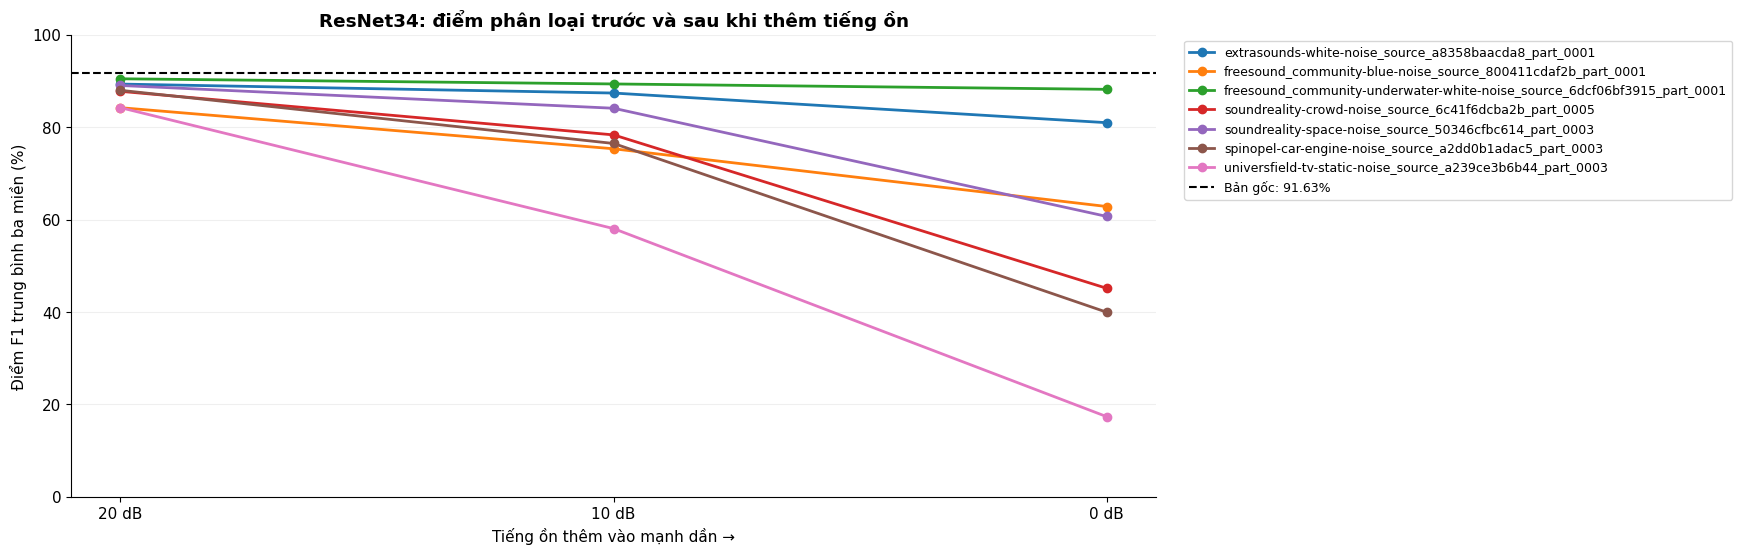

In [21]:
figure, axis = plt.subplots(figsize=(14, 6))
for noise_id in noise_ids:
    scores = condition_scores[condition_scores.noise_id.eq(noise_id)].set_index('snr_db')
    axis.plot(range(len(snr_levels)), scores.loc[snr_levels, 'macro_f1'] * 100,
              marker='o', linewidth=2, color=colors[noise_id], label=noise_names[noise_id])
axis.axhline(baseline_f1 * 100, color='black', linestyle='--',
             label=f'Bản gốc: {baseline_f1 * 100:.2f}%')
axis.set(xticks=range(len(snr_levels)), xticklabels=[f'{value:g} dB' for value in snr_levels],
         ylim=(0, 100), ylabel='Điểm F1 trung bình ba miền (%)', xlabel='Tiếng ồn thêm vào mạnh dần →',
         title='ResNet34: điểm phân loại trước và sau khi thêm tiếng ồn')
axis.grid(axis='y', alpha=0.2)
axis.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
show_figure(figure, '01_macro_f1_by_snr.png')

## 2. Tệp tiếng ồn nào làm kết quả giảm nhiều nhất?

Hai bảng màu hiển thị con số cho từng tệp nhiễu và từng mức tiếng ồn:
- **Bảng trái:** điểm phân loại sau khi thêm nhiễu. Số càng cao càng tốt.
- **Bảng phải:** điểm bị giảm so với bản gốc. Số dương càng lớn nghĩa là giảm càng nhiều; số âm nghĩa là điểm tăng.

Các tệp được xếp theo mức giảm trung bình ở những SNR đang khảo sát. Thứ tự này chỉ đúng với các tệp và các mức đã thử, chưa nói được loại tiếng ồn nào luôn khó nhất.

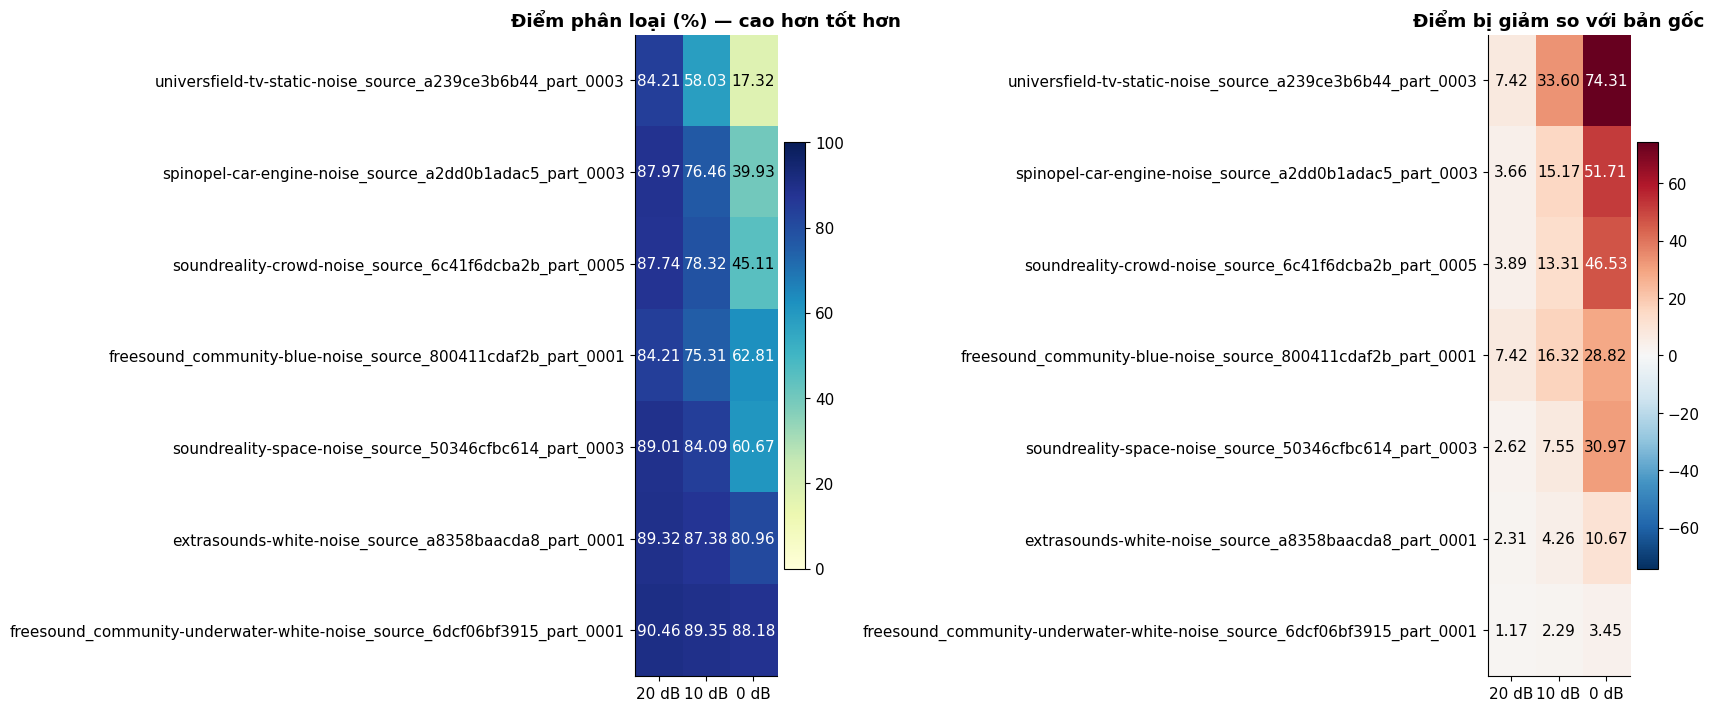

snr_db,20.0,10.0,0.0
noise_id,,,
universfield-tv-static-noise_source_a239ce3b6b44_part_0003,84.21,58.03,17.32
spinopel-car-engine-noise_source_a2dd0b1adac5_part_0003,87.97,76.46,39.93
soundreality-crowd-noise_source_6c41f6dcba2b_part_0005,87.74,78.32,45.11
freesound_community-blue-noise_source_800411cdaf2b_part_0001,84.21,75.31,62.81
soundreality-space-noise_source_50346cfbc614_part_0003,89.01,84.09,60.67
extrasounds-white-noise_source_a8358baacda8_part_0001,89.32,87.38,80.96
freesound_community-underwater-white-noise_source_6dcf06bf3915_part_0001,90.46,89.35,88.18


In [22]:
f1_table = condition_scores.pivot(index='noise_id', columns='snr_db', values='macro_f1') * 100
drop_table = condition_scores.pivot(index='noise_id', columns='snr_db', values='f1_drop_points')
noise_order = drop_table.mean(axis=1).sort_values(ascending=False).index
f1_table = f1_table.reindex(index=noise_order, columns=snr_levels)
drop_table = drop_table.reindex(index=noise_order, columns=snr_levels)
figure, axes = plt.subplots(1, 2, figsize=(17, 7), layout='constrained')
for axis, table, title, color_map, minimum, maximum in [
    (axes[0], f1_table, 'Điểm phân loại (%) — cao hơn tốt hơn', 'YlGnBu', 0, 100),
    (axes[1], drop_table, 'Điểm bị giảm so với bản gốc', 'RdBu_r',
     -max(1, abs(drop_table.to_numpy()).max()), max(1, abs(drop_table.to_numpy()).max()))]:
    chart = axis.imshow(table.to_numpy(), cmap=color_map, vmin=minimum, vmax=maximum, aspect='auto')
    axis.set(xticks=range(len(snr_levels)), xticklabels=[f'{value:g} dB' for value in snr_levels],
             yticks=range(len(table)), yticklabels=[noise_names[key] for key in table.index], title=title)
    for row_number in range(len(table)):
        for column_number in range(len(snr_levels)):
            value = table.iloc[row_number, column_number]
            rgba = chart.cmap(chart.norm(value))
            brightness = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
            axis.text(column_number, row_number, f'{value:.2f}', ha='center', va='center',
                      color='black' if brightness > 0.55 else 'white')
    figure.colorbar(chart, ax=axis, shrink=0.7)
show_figure(figure, '02_f1_heatmaps.png')
display(f1_table.rename(index=noise_names).round(2))

## 3. Bao nhiêu đoạn đang đoán đúng thì bị đoán sai khi thêm nhiễu?

Ví dụ: bản gốc có 100 đoạn được đoán đúng; thêm tiếng ồn khiến 20 đoạn trong số đó bị đoán sai thì tỷ lệ là 20%.

Cột càng dài nghĩa là càng mất nhiều dự đoán đúng. Mẫu số chỉ gồm các đoạn được đoán đúng ở bản gốc. Nếu đã thử nhiều lần chọn đoạn nhiễu, biểu đồ lấy trung bình tỷ lệ các lần.

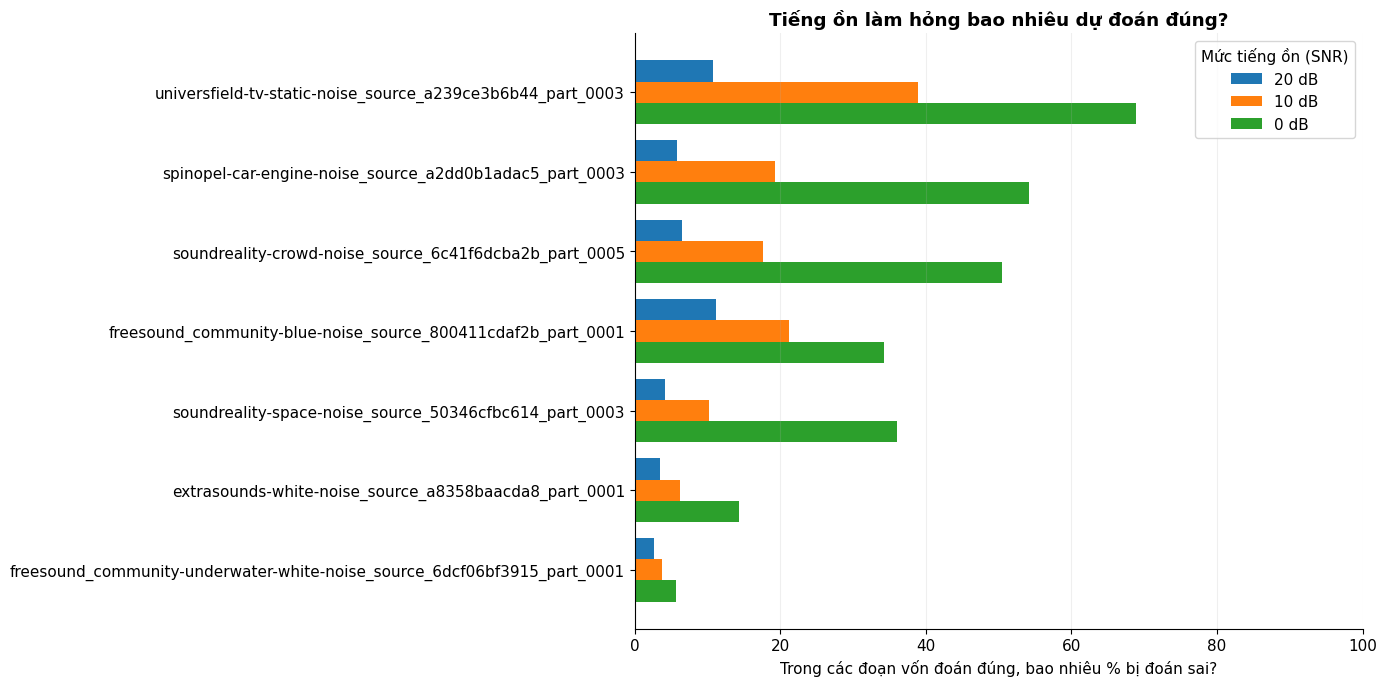

In [23]:
figure, axis = plt.subplots(figsize=(14, 7))
bar_width = 0.8 / len(snr_levels)
positions = np.arange(len(noise_order))
for index, snr in enumerate(snr_levels):
    rates = condition_scores[condition_scores.snr_db.eq(snr)].set_index('noise_id')
    values = rates.loc[noise_order, 'correct_to_wrong_rate'] * 100
    axis.barh(positions + (index - (len(snr_levels) - 1) / 2) * bar_width,
              values, height=bar_width, label=f'{snr:g} dB')
axis.set(yticks=positions, yticklabels=[noise_names[key] for key in noise_order],
         xlim=(0, 100), xlabel='Trong các đoạn vốn đoán đúng, bao nhiêu % bị đoán sai?',
         title='Tiếng ồn làm hỏng bao nhiêu dự đoán đúng?')
axis.invert_yaxis()
axis.grid(axis='x', alpha=0.2)
axis.legend(title='Mức tiếng ồn (SNR)')
figure.tight_layout()
show_figure(figure, '03_correct_to_wrong.png')

## 4. Giọng Bắc, Trung, Nam bị nhầm thành giọng nào?

Mặc định xem trường hợp có Macro-F1 trung bình thấp nhất. Bạn có thể đổi `SELECTED_NOISE_ID` (tệp nhiễu), `SELECTED_SNR` (mức nhiễu) và `SELECTED_REPEAT` (lần chọn đoạn nhiễu).

### Cách đọc bảng
- **Hàng:** giọng thật của đoạn nói.
- **Cột:** giọng mà mô hình đoán.
- **Ô trên đường chéo:** đoán đúng; ô còn lại là nhầm sang miền khác.
- Mỗi hàng cộng lại 100%. Ví dụ hàng Bắc, cột Trung bằng 60% nghĩa là 60% đoạn giọng Bắc bị đoán thành Trung.

Biểu đồ cột phía sau so sánh số đoạn thật với số đoạn mô hình gán cho mỗi miền. Nếu gần như đoạn nào cũng bị đoán là Trung, kết quả không tốt dù mô hình nhận đúng nhiều đoạn Trung.

Đang xem tệp nhiễu: universfield-tv-static-noise_source_a239ce3b6b44_part_0003 | SNR: 0.0 | Lần chọn đoạn nhiễu: 0


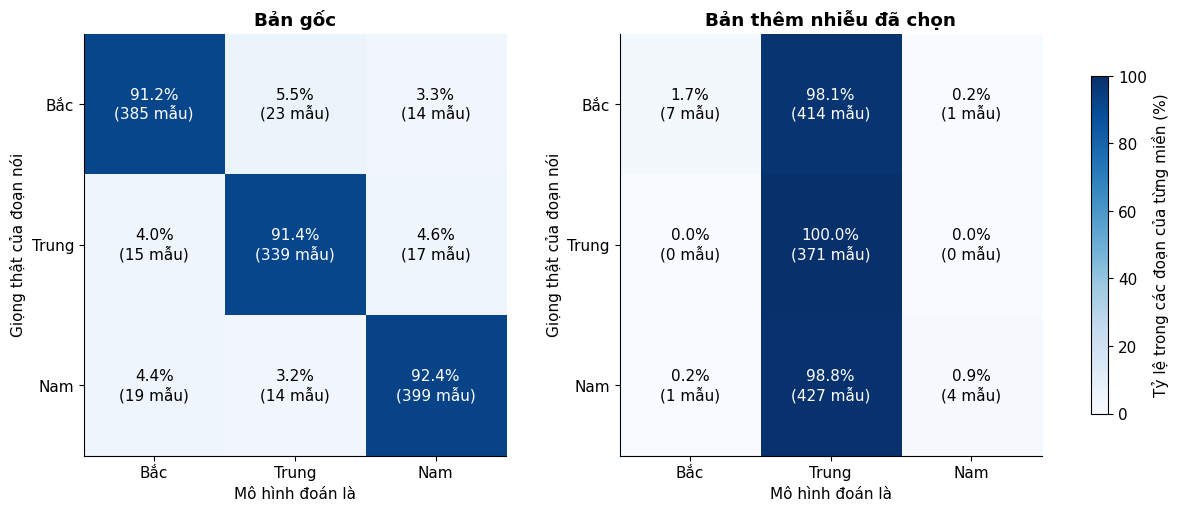

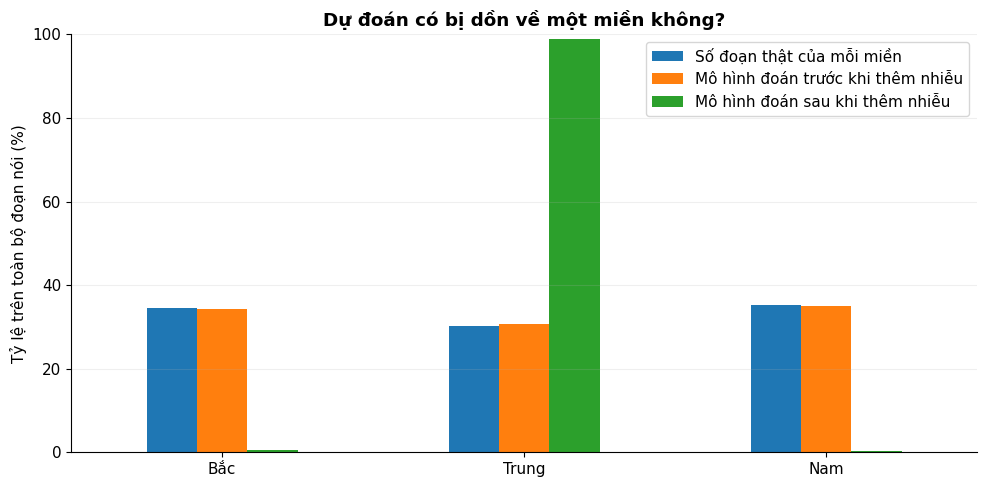

,Số đoạn thật của mỗi miền,Mô hình đoán trước khi thêm nhiễu,Mô hình đoán sau khi thêm nhiễu
Bắc,422,419,8
Trung,371,376,1212
Nam,432,430,5


In [24]:
worst_condition = condition_scores.loc[condition_scores.macro_f1.idxmin()]
SELECTED_NOISE_ID = worst_condition.noise_id
SELECTED_SNR = float(worst_condition.snr_db)
SELECTED_REPEAT = int(noisy_summary[
    noisy_summary.noise_id.eq(SELECTED_NOISE_ID) & noisy_summary.snr_db.eq(SELECTED_SNR)
].repeat_id.min())
selected_predictions = noisy_predictions[
    noisy_predictions.noise_id.eq(SELECTED_NOISE_ID)
    & noisy_predictions.snr_db.eq(SELECTED_SNR)
    & noisy_predictions.repeat_id.eq(SELECTED_REPEAT)]
print('Đang xem tệp nhiễu:', noise_names[SELECTED_NOISE_ID], '| SNR:', SELECTED_SNR, '| Lần chọn đoạn nhiễu:', SELECTED_REPEAT)
figure, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for axis, data, title in [(axes[0], original_predictions, 'Bản gốc'),
                          (axes[1], selected_predictions, 'Bản thêm nhiễu đã chọn')]:
    counts = confusion_matrix(data.true_label, data.predicted_label, labels=[0, 1, 2])
    totals = counts.sum(axis=1, keepdims=True)
    percentages = np.divide(counts * 100.0, totals, out=np.zeros_like(counts, dtype=float), where=totals != 0)
    chart = axis.imshow(percentages, cmap='Blues', vmin=0, vmax=100)
    axis.set(xticks=range(3), xticklabels=dialect_names, yticks=range(3), yticklabels=dialect_names,
             xlabel='Mô hình đoán là', ylabel='Giọng thật của đoạn nói', title=title)
    for row_number in range(3):
        for column_number in range(3):
            value = percentages[row_number, column_number]
            axis.text(column_number, row_number,
                      f'{value:.1f}%\n({counts[row_number, column_number]} mẫu)',
                      ha='center', va='center', color='white' if value > 55 else 'black')
figure.colorbar(chart, ax=axes, label='Tỷ lệ trong các đoạn của từng miền (%)', shrink=0.8)
show_figure(figure, '04_confusion_original_vs_noisy.png')

# So sánh cơ cấu nhãn thật và cơ cấu nhãn mô hình dự đoán.
label_counts = pd.DataFrame({
    'Số đoạn thật của mỗi miền': original_predictions.true_label.value_counts().reindex(range(3), fill_value=0),
    'Mô hình đoán trước khi thêm nhiễu': original_predictions.predicted_label.value_counts().reindex(range(3), fill_value=0),
    'Mô hình đoán sau khi thêm nhiễu': selected_predictions.predicted_label.value_counts().reindex(range(3), fill_value=0)
})
label_counts.index = dialect_names
axis = (label_counts / len(original_predictions) * 100).plot.bar(figsize=(10, 5), rot=0)
axis.set(ylabel='Tỷ lệ trên toàn bộ đoạn nói (%)', title='Dự đoán có bị dồn về một miền không?', ylim=(0, 100))
axis.grid(axis='y', alpha=0.2)
figure = axis.figure
figure.tight_layout()
show_figure(figure, '05_prediction_distribution.png')
display(label_counts)

## 5. Mô hình còn nhận đúng được bao nhiêu đoạn của từng miền?

Mỗi biểu đồ nhỏ tương ứng một tệp nhiễu. Ba đường màu tương ứng Bắc, Trung, Nam.

Ví dụ: miền Nam có 100 đoạn, nhận đúng 70 đoạn thì tỷ lệ nhận đúng riêng miền Nam (Recall) là 70%. Đường đứt cùng màu là kết quả trước khi thêm nhiễu.

Nếu đường Trung vẫn cao nhưng Bắc và Nam giảm mạnh, hãy kiểm tra bảng ở phần 4: mô hình có thể đang gán cả giọng Bắc/Nam thành Trung. Tỷ lệ nhận đúng riêng một miền không phản ánh toàn bộ chất lượng.

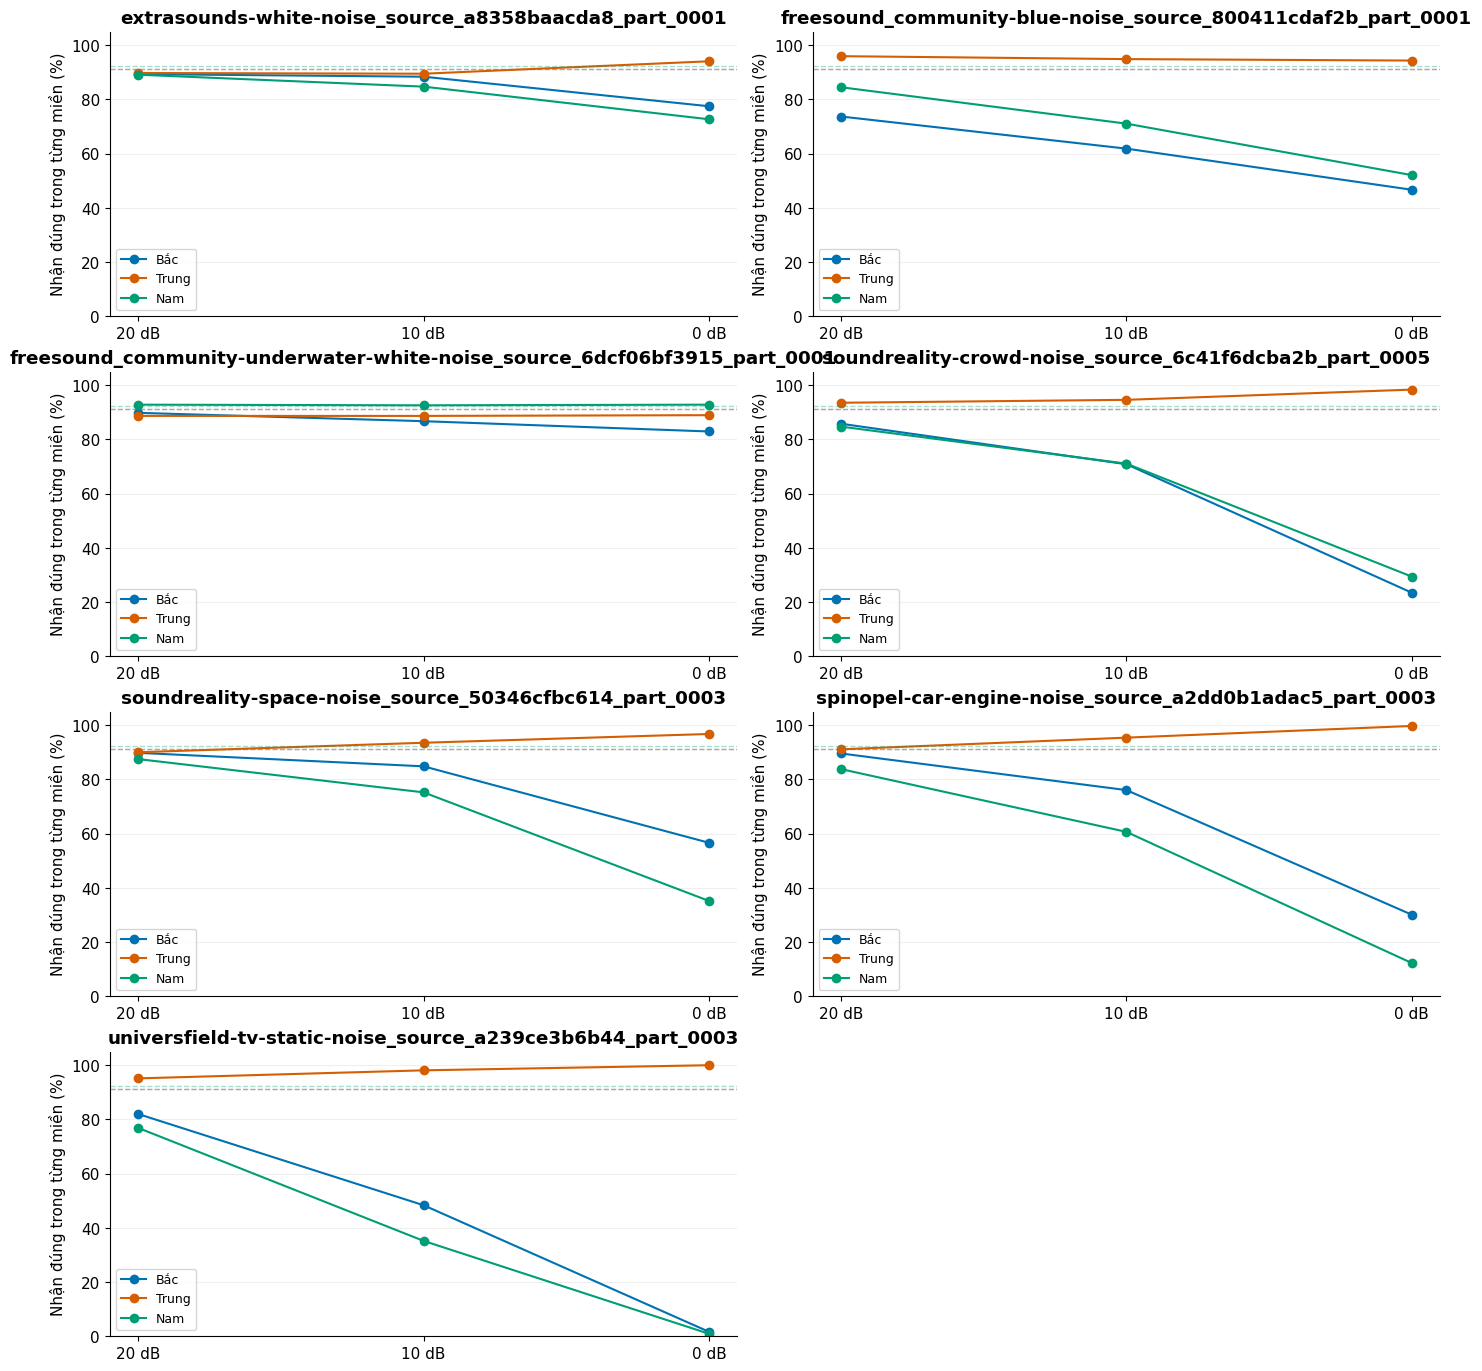

In [25]:
number_of_columns = 2
number_of_rows = int(np.ceil(len(noise_ids) / number_of_columns))
figure, axes = plt.subplots(number_of_rows, number_of_columns,
                            figsize=(14, 3.4 * number_of_rows), squeeze=False, layout='constrained')
recall_columns = ['recall_north', 'recall_central', 'recall_south']
for axis, noise_id in zip(axes.flat, noise_ids):
    scores = condition_scores[condition_scores.noise_id.eq(noise_id)].set_index('snr_db')
    for column, name, color in zip(recall_columns, dialect_names, ['#0072B2', '#D55E00', '#009E73']):
        axis.plot(range(len(snr_levels)), scores.loc[snr_levels, column] * 100,
                  marker='o', color=color, label=name)
        axis.axhline(float(original_summary.iloc[0][column]) * 100, linestyle='--',
                     color=color, alpha=0.35, linewidth=1)
    axis.set(title=noise_names[noise_id], xticks=range(len(snr_levels)),
             xticklabels=[f'{snr:g} dB' for snr in snr_levels], ylim=(0, 105), ylabel='Nhận đúng trong từng miền (%)')
    axis.grid(axis='y', alpha=0.2)
    axis.legend(fontsize=9)
for axis in list(axes.flat)[len(noise_ids):]:
    axis.set_visible(False)
show_figure(figure, '06_recall_by_dialect.png')

## 6. Kết quả cho biết điều gì và nên làm gì tiếp?

Phần nhận xét bên dưới tự lấy số từ các bảng kết quả. Không phải số liệu giả định. Các nhận xét chỉ áp dụng cho dữ liệu và những tệp tiếng ồn đã thử.

In [26]:
worst_name = noise_names[worst_condition.noise_id]
repeat_counts = noisy_summary.groupby(['noise_id', 'snr_db']).size()
selected_correct_to_wrong = int(((selected_predictions.set_index('audio_id').predicted_label
    != original_predictions.set_index('audio_id').true_label)
    & (original_predictions.set_index('audio_id').predicted_label
       == original_predictions.set_index('audio_id').true_label)).sum())
majority_label = int(selected_predictions.predicted_label.value_counts().idxmax())
majority_count = int((selected_predictions.predicted_label == majority_label).sum())
display(Markdown(f'''
### Kết quả trước khi thêm tiếng ồn
Mô hình đoán đúng **{float(original_summary.iloc[0].accuracy) * 100:.2f}%** tổng số đoạn nói.
Điểm F1 trung bình của ba miền là **{baseline_f1 * 100:.2f}%**. Hai con số này đo những mặt khác nhau của kết quả.

### Trường hợp có điểm thấp nhất
Với tệp **{worst_name}** ở mức **{worst_condition.snr_db:g} dB**, điểm F1 trung bình còn
**{worst_condition.macro_f1 * 100:.2f}%**, giảm **{worst_condition.f1_drop_points:.2f} điểm phần trăm** so với bản gốc.
Đây là trường hợp thấp nhất trong những tệp và mức tiếng ồn đã thử, không có nghĩa là khó nhất trong mọi môi trường thực tế.

### Trường hợp đang mở ở phần 4
Tệp: **{noise_names[SELECTED_NOISE_ID]}**, mức **{SELECTED_SNR:g} dB**, lần chọn đoạn nhiễu số **{SELECTED_REPEAT + 1}**.
Mô hình gán **{majority_count}/{len(selected_predictions)} đoạn** là giọng **{dialect_names[majority_label]}**.
Có **{selected_correct_to_wrong} đoạn vốn đoán đúng ở bản gốc nhưng trở thành sai** sau khi thêm nhiễu.
Cần nhìn cùng số đoạn thật của mỗi miền ở bảng trên để biết mô hình có đang đoán lệch về một miền hay không.

### Có thể kết luận gì lúc này?
Trong lần thử này, cùng một đoạn nói có thể bị nhận diện sai sau khi thêm tiếng ồn.
Đây là cơ sở ban đầu để nghiên cứu cách giúp mô hình ít bị tiếng ồn ảnh hưởng hơn.
Kết quả chưa chỉ ra chắc chắn vì sao mô hình sai, hoặc cách huấn luyện nào sẽ khắc phục được.

### Việc cần kiểm tra tiếp
1. Nghe thử vài bản âm thanh đã trộn để kiểm tra tiếng ồn và chất lượng âm thanh.
2. Hiện mỗi tệp ở mỗi mức SNR được thử từ **{int(repeat_counts.min())} đến {int(repeat_counts.max())} lần chọn đoạn nhiễu**.
   Nếu chỉ một lần, cần thử thêm đoạn cắt khác để xem kết quả có lặp lại không.
3. Thử thêm những bản ghi tiếng ồn khác. Cắt nhiều đoạn từ một tệp không thay thế được việc dùng nhiều nguồn khác nhau.
4. Dùng kết quả này để chọn cách cải thiện; sau khi chốt mới đánh giá cuối trên tập test riêng.
5. Kiểm tra người nói có xuất hiện ở cả tập huấn luyện và validation không, trước khi kết luận mô hình làm tốt với người chưa gặp.
'''))


### Kết quả trước khi thêm tiếng ồn
Mô hình đoán đúng **91.67%** tổng số đoạn nói.
Điểm F1 trung bình của ba miền là **91.63%**. Hai con số này đo những mặt khác nhau của kết quả.

### Trường hợp có điểm thấp nhất
Với tệp **universfield-tv-static-noise_source_a239ce3b6b44_part_0003** ở mức **0 dB**, điểm F1 trung bình còn
**17.32%**, giảm **74.31 điểm phần trăm** so với bản gốc.
Đây là trường hợp thấp nhất trong những tệp và mức tiếng ồn đã thử, không có nghĩa là khó nhất trong mọi môi trường thực tế.

### Trường hợp đang mở ở phần 4
Tệp: **universfield-tv-static-noise_source_a239ce3b6b44_part_0003**, mức **0 dB**, lần chọn đoạn nhiễu số **1**.
Mô hình gán **1212/1225 đoạn** là giọng **Trung**.
Có **773 đoạn vốn đoán đúng ở bản gốc nhưng trở thành sai** sau khi thêm nhiễu.
Cần nhìn cùng số đoạn thật của mỗi miền ở bảng trên để biết mô hình có đang đoán lệch về một miền hay không.

### Có thể kết luận gì lúc này?
Trong lần thử này, cùng một đoạn nói có thể bị nhận diện sai sau khi thêm tiếng ồn.
Đây là cơ sở ban đầu để nghiên cứu cách giúp mô hình ít bị tiếng ồn ảnh hưởng hơn.
Kết quả chưa chỉ ra chắc chắn vì sao mô hình sai, hoặc cách huấn luyện nào sẽ khắc phục được.

### Việc cần kiểm tra tiếp
1. Nghe thử vài bản âm thanh đã trộn để kiểm tra tiếng ồn và chất lượng âm thanh.
2. Hiện mỗi tệp ở mỗi mức SNR được thử từ **1 đến 1 lần chọn đoạn nhiễu**.
   Nếu chỉ một lần, cần thử thêm đoạn cắt khác để xem kết quả có lặp lại không.
3. Thử thêm những bản ghi tiếng ồn khác. Cắt nhiều đoạn từ một tệp không thay thế được việc dùng nhiều nguồn khác nhau.
4. Dùng kết quả này để chọn cách cải thiện; sau khi chốt mới đánh giá cuối trên tập test riêng.
5. Kiểm tra người nói có xuất hiện ở cả tập huấn luyện và validation không, trước khi kết luận mô hình làm tốt với người chưa gặp.


## 7. Nghe bản gốc và các bản thêm tiếng ồn

Chỉ có dữ liệu nghe sau khi chạy script đánh giá phiên bản mới với `save_audio_examples: true`. Lần chạy cũ vẫn xem được các biểu đồ trước đó.

Mỗi nhóm gồm cùng đoạn nói, cùng tệp nhiễu và các mức SNR. Các tệp trong nhóm đã được giảm âm lượng bằng **cùng một hệ số** để tránh méo do vượt biên độ khi nghe. Đầu vào đánh giá mô hình không bị thay đổi. Không so âm lượng tuyệt đối giữa hai nhóm khác nhau. Trình phát bên dưới không tự chuẩn hóa âm lượng từng tệp.

Chọn mã nhiễu và mã đoạn nói bên dưới. Nghe lần lượt để kiểm tra: đúng đoạn nói, nhiễu mạnh dần khi SNR giảm, không bị lỗi cắt/âm thanh bất thường. Notebook không tự phát âm thanh.

In [27]:
from IPython.display import Audio

LISTEN_NOISE_ID = SELECTED_NOISE_ID
LISTEN_AUDIO_ID = None  # None: lấy mẫu nghe đầu tiên của tệp nhiễu đã chọn.
example_list_path = results_folder / 'audio_examples.csv'
if not example_list_path.exists():
    print('Lần chạy này chưa lưu mẫu nghe. Cần chạy script đánh giá mới với chức năng lưu mẫu nghe bật.')
else:
    examples = pd.read_csv(example_list_path)
    available_examples = examples[examples.noise_id.eq(LISTEN_NOISE_ID)]
    if available_examples.empty:
        print('Không có mẫu nghe cho mã nhiễu này. Các mã có mẫu:', examples.noise_id.unique())
    else:
        audio_id = available_examples.audio_id.iloc[0] if LISTEN_AUDIO_ID is None else LISTEN_AUDIO_ID
        listening_group = available_examples[available_examples.audio_id.eq(audio_id)]
        if listening_group.empty:
            print('Không có mẫu nghe cho audio_id đã chọn.')
        for example in listening_group.itertuples():
            description = 'Bản gốc' if example.condition == 'original' else f'Thêm nhiễu {example.snr_db:g} dB'
            display(Markdown(f'**{description}** — giọng thật: **{dialect_names[int(example.true_label)]}**; '
                             f'đoạn số {example.audio_id}; hệ số nghe chung {example.listening_gain:.4f}'))
            display(Audio(filename=str(results_folder / example.path), normalize=False))

**Bản gốc** — giọng thật: **Trung**; đoạn số 0; hệ số nghe chung 1.0000

**Thêm nhiễu 20 dB** — giọng thật: **Trung**; đoạn số 0; hệ số nghe chung 1.0000

**Thêm nhiễu 10 dB** — giọng thật: **Trung**; đoạn số 0; hệ số nghe chung 1.0000

**Thêm nhiễu 0 dB** — giọng thật: **Trung**; đoạn số 0; hệ số nghe chung 1.0000

## 8. Kiểm tra cách trộn có đúng SNR không?

SNR đo lại phải gần với mức yêu cầu. `snr_error_db` là độ lệch giữa hai giá trị; script dùng mức kiểm tra 0,05 dB. Đây là kiểm tra số học, không chứng minh tiếng ồn thực tế hay bản ghi phù hợp.

Biên độ vượt 1 trước khi lưu mẫu nghe không tự động là clipping: mô hình nhận dữ liệu float, không cắt ngọn. Cột này giúp nhận biết tín hiệu lớn và đối chiếu khác biệt về âm lượng. Nhiễu ngắn bị lặp hoặc chỉ có một vị trí cắt thì tăng repeats không tạo thêm sự đa dạng đáng kể.

In [28]:
signal_checks_path = results_folder / 'signal_checks.csv'
if not signal_checks_path.exists():
    print('Lần chạy cũ chưa có signal_checks.csv. Không suy đoán rằng tín hiệu đã được kiểm tra.')
else:
    checks = pd.read_csv(signal_checks_path)
    matching = checks.snr_matches.astype(str).str.lower().eq('true')
    finite = checks.finite.astype(str).str.lower().eq('true')
    display(pd.DataFrame({
        'Nội dung kiểm tra': ['Số bản trộn', 'SNR lệch từ 0,05 dB trở lên hoặc không xác định',
                              'Bản trộn có giá trị không hợp lệ', 'Độ lệch SNR lớn nhất (dB)',
                              'Biên độ lớn nhất trước khi giảm âm lượng để nghe'],
        'Kết quả': [len(checks), int((~matching).sum()), int((~finite).sum()),
                    checks.snr_error_db.max(), checks.peak_before_listening_gain.max()]}))
    display(checks.groupby('noise_id').agg(
        so_vi_tri_cat_it_nhat=('available_noise_start_positions', 'min'),
        sai_so_snr_lon_nhat_db=('snr_error_db', 'max'),
        bien_do_lon_nhat=('peak_before_listening_gain', 'max')))
    if not matching.all() or not finite.all():
        print('Có bản trộn cần kiểm tra trước khi sử dụng kết luận.')

,Nội dung kiểm tra,Kết quả
0,Số bản trộn,2.572500e+04
1,"SNR lệch từ 0,05 dB trở lên hoặc không xác định",0.000000e+00
2,Bản trộn có giá trị không hợp lệ,0.000000e+00
3,Độ lệch SNR lớn nhất (dB),5.192598e-07
4,Biên độ lớn nhất trước khi giảm âm lượng để nghe,2.146252e+00


,so_vi_tri_cat_it_nhat,sai_so_snr_lon_nhat_db,bien_do_lon_nhat
noise_id,,,
source_50346cfbc614_part_0003,1,5.078695e-07,1.767225
source_6c41f6dcba2b_part_0005,1,5.192598e-07,1.875507
source_6dcf06bf3915_part_0001,1,5.103308e-07,1.838105
source_800411cdaf2b_part_0001,1,5.098935e-07,1.922525
source_a239ce3b6b44_part_0003,1,5.066616e-07,1.993984
source_a2dd0b1adac5_part_0003,1,5.141899e-07,2.146252
source_a8358baacda8_part_0001,1,5.120381e-07,1.793532


## 9. Đổi đoạn nhiễu thì kết quả dao động bao nhiêu?

Mỗi biểu đồ nhỏ là một tệp. Đường là Macro-F1 trung bình, vùng màu là **thấp nhất–cao nhất qua các lần chọn đoạn nhiễu**. Đây không phải khoảng tin cậy thống kê hoặc độ ổn định qua nhiều lần huấn luyện. Nếu chỉ có một lần chọn, chưa đo được dao động.

In [29]:
repeat_totals = noisy_summary.groupby(['noise_id', 'snr_db']).size()
if repeat_totals.max() < 2:
    print('Lần chạy này chỉ có một lần chọn đoạn nhiễu mỗi điều kiện. Chưa có dữ liệu để đánh giá dao động.')
else:
    figure, axes = plt.subplots(int(np.ceil(len(noise_ids) / 2)), 2,
                                figsize=(14, 3.4 * int(np.ceil(len(noise_ids) / 2))),
                                squeeze=False, layout='constrained')
    for axis, noise_id in zip(axes.flat, noise_ids):
        repeated_scores = noisy_summary[noisy_summary.noise_id.eq(noise_id)].groupby('snr_db').macro_f1.agg(['mean', 'min', 'max', 'count'])
        repeated_scores = repeated_scores.reindex(snr_levels)
        positions = np.arange(len(snr_levels))
        axis.plot(positions, repeated_scores['mean'].to_numpy() * 100, marker='o', color=colors[noise_id])
        axis.fill_between(positions, repeated_scores['min'].to_numpy() * 100,
                           repeated_scores['max'].to_numpy() * 100, alpha=0.2, color=colors[noise_id])
        axis.axhline(baseline_f1 * 100, color='black', linestyle='--', alpha=0.5)
        axis.set(title=noise_names[noise_id], xticks=positions,
                 xticklabels=[f'{snr:g} dB' for snr in snr_levels], ylim=(0, 100),
                 ylabel='Điểm F1 trung bình ba miền (%)')
        axis.grid(axis='y', alpha=0.2)
    for axis in list(axes.flat)[len(noise_ids):]:
        axis.set_visible(False)
    show_figure(figure, '07_variation_across_noise_segments.png')

Lần chạy này chỉ có một lần chọn đoạn nhiễu mỗi điều kiện. Chưa có dữ liệu để đánh giá dao động.


## 10. Cách thêm nhiễu lúc train đã tạo SNR như thế nào?

Chạy riêng `inspect_training_augmentation.py` khi bạn muốn tạo dữ liệu cho phần này. Sau đó điền tên thư mục kết quả vào `AUGMENTATION_RUN_NAME` dưới đây. Notebook không tự chạy script đó.

Script khảo sát một nhóm mẫu train, thử từng mức Gaussian và từng tệp nền bằng công thức hiện tại. Không tái hiện chính xác những bản trộn mô hình đã gặp, không phản ánh tần suất các phép augmentation trong lịch sử train, không đo thay đổi tốc độ hoặc vang bằng SNR cộng nhiễu. Gaussian có clip, nên SNR trước clip và sau clip có thể khác nhau.

Nếu SNR train có bao phủ 0/10/20 dB thì vẫn chưa chứng minh mô hình đã học tốt ở các mức đó: loại nhiễu, âm lượng, khoảng lặng và số lần xuất hiện cũng ảnh hưởng.

,Số phép đo hợp lệ,SNR nhỏ nhất,SNR ở giữa,SNR lớn nhất
Nhóm nhiễu,,,,
146693_traffic_music,180,-7.30,7.14,15.37
158480_music_bird_street,180,5.49,22.11,32.52
189846_dogbark,180,-2.54,12.36,21.37
199730__waveadventurer__footsteps-inside-medium-sized-store,180,5.89,19.16,25.88
451117_street_distanttalking_music,180,5.74,19.63,26.99
673957_rain,180,12.57,25.25,31.99
716453_piano,180,3.87,16.96,23.80
745032_piano,180,-3.30,12.40,25.51
"Gaussian, mức 0.0008",180,27.12,39.74,46.48


C:\Users\Uyen\AppData\Local\Temp\ipykernel_3512\2790116522.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot([values for name, values in valid_groups], vert=False,


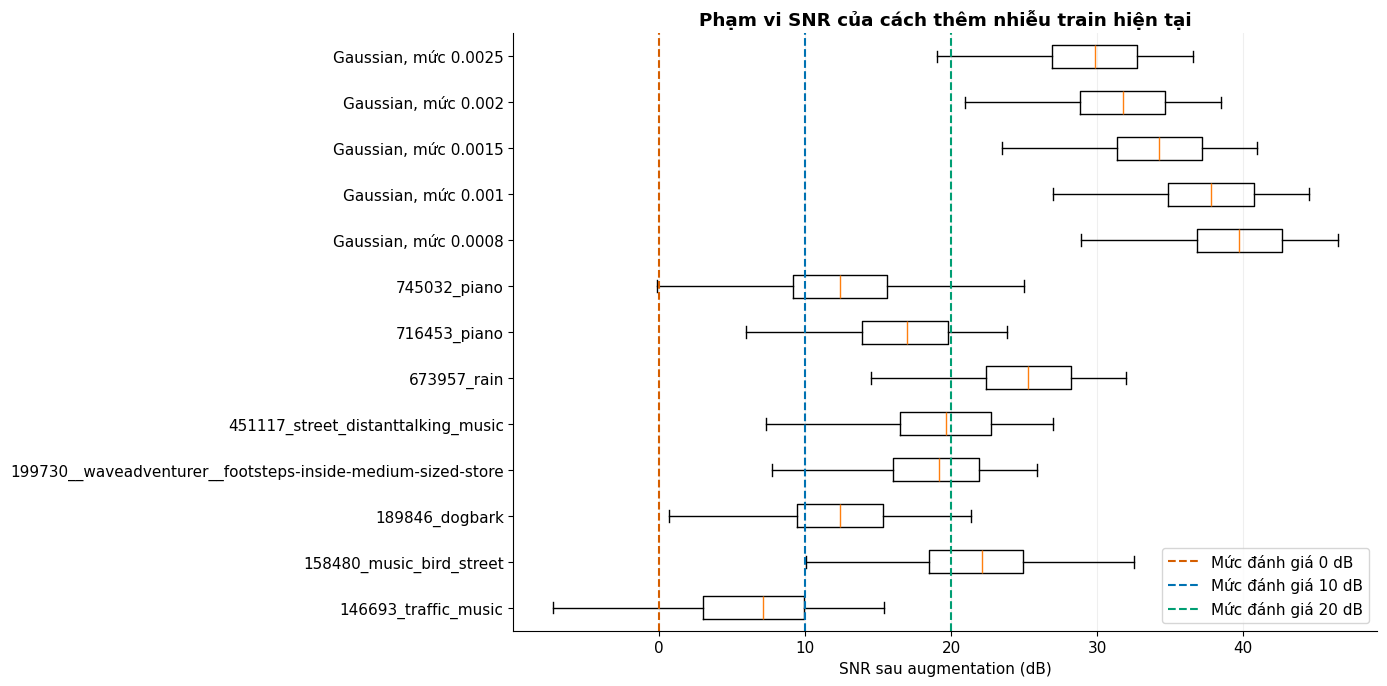

Các giá trị SNR không xác định: 0
Hộp là nửa giữa của các phép đo; nét trong hộp là trung vị. Điểm ngoại lệ không vẽ nhưng vẫn có trong CSV.


In [31]:
AUGMENTATION_RUN_NAME = '20261018_222001_bb877126'  # Ví dụ: '20261018_220000_abcdefgh'; không tự chọn lần mới nhất.
if AUGMENTATION_RUN_NAME is None:
    print('Chưa chọn kết quả kiểm tra augmentation. Điền tên thư mục sau khi bạn tự chạy script kiểm tra.')
else:
    augmentation_folder = project_folder / 'logs' / 'training_augmentation_check' / AUGMENTATION_RUN_NAME
    with (augmentation_folder / 'run_info.json').open(encoding='utf-8') as file:
        augmentation_information = json.load(file)
    if augmentation_information.get('status') != 'completed':
        raise ValueError('Lần kiểm tra augmentation chưa hoàn tất.')
    augmentation_data = pd.read_csv(augmentation_folder / 'augmentation_snr.csv')
    augmentation_data['Nhóm nhiễu'] = augmentation_data.apply(
        lambda row: f'Gaussian, mức {row.gaussian_std:g}' if row.augmentation == 'gaussian'
        else Path(str(row.noise_file)).stem, axis=1)
    display(augmentation_data.groupby('Nhóm nhiễu').effective_snr_db.agg(
        ['count', 'min', 'median', 'max']).rename(columns={
            'count': 'Số phép đo hợp lệ', 'min': 'SNR nhỏ nhất',
            'median': 'SNR ở giữa', 'max': 'SNR lớn nhất'}).round(2))
    groups = list(augmentation_data.groupby('Nhóm nhiễu', sort=True))
    values = [group.effective_snr_db.dropna().to_numpy() for name, group in groups]
    valid_groups = [(name, group_values) for (name, group), group_values in zip(groups, values) if len(group_values)]
    if valid_groups:
        figure, axis = plt.subplots(figsize=(14, 7))
        axis.boxplot([values for name, values in valid_groups], vert=False,
                      labels=[name for name, values in valid_groups], showfliers=False)
        for snr, color in zip([0, 10, 20], ['#D55E00', '#0072B2', '#009E73']):
            axis.axvline(snr, linestyle='--', color=color, label=f'Mức đánh giá {snr} dB')
        axis.set(xlabel='SNR sau augmentation (dB)', title='Phạm vi SNR của cách thêm nhiễu train hiện tại')
        axis.legend()
        axis.grid(axis='x', alpha=0.2)
        figure.tight_layout()
        show_figure(figure, '08_training_augmentation_snr.png')
    print('Các giá trị SNR không xác định:', int(augmentation_data.effective_snr_db.isna().sum()))
    print('Hộp là nửa giữa của các phép đo; nét trong hộp là trung vị. Điểm ngoại lệ không vẽ nhưng vẫn có trong CSV.')